# Reproducing GRAHSP's AGN physics with tengri

GRAHSP (Buchner et al. 2024, A&A 692, A161; arXiv:2405.19297) fits galaxy spectra with an AGN
model built from a smooth big-blue bump, emission lines and a FeII forest, an infrared torus
with a silicate feature, and bi-attenuation. Its authors released the model as pcigale
modules. This page compares tengri's GRAHSP blocks with upstream GRAHSP's own spectra,
component by component, and then in full.

The page uses six of the 38 parameter sets in the reference: the fiducial, two Balmer-continuum
sets, two torus-width sets, and the type-2 set. The Netzer and MN12 comparisons use the fiducial.
The attenuation comparison uses two of the E(B-V) sets. tengri is evaluated only through the
public `SEDModel.build` grammar and `model.predict`, on the model's own wavelength grid.
Upstream is interpolated linearly in wavelength onto that grid, which is upstream's own
convention for its tabulated templates.

**Reading guide.** Every figure prints the largest disagreement it shows, as max |log10 ratio|
in dex, over the points both codes define. Figures plot $L_\nu$ [erg/s/Hz]. Three upstream
conventions are applied to upstream's values before comparison: the emission-line normalization
(divide by $\sqrt{2}$, Sect. 2.1.2), the torus width (paper Eq. 2), and the 510 normalization of
the Netzer disc and MN12 torus (divide by 510, Eqs. 1 and 4). Section 2 shows that upstream's
lines are also rendered wider than their Gaussians, and section 5 shows where the Netzer and MN12
templates are interpolated differently.

| Component | tengri block | Agreement, fiducial (max \|Δ\|, dex) | Section |
|---|---|---|---|
| Big blue bump (smooth bending power law) | `grahsp_sbpl` | 2.8×10⁻⁶ | 1 |
| Torus (log-Gaussian) and Si feature | `grahsp` | 5.3×10⁻³ | 1, 4 |
| Emission lines: flux and centroid | `grahsp` (nlr, blr) | 2.8% per window; centroid 0.08 nm | 2 |
| Balmer continuum | `grahsp` (blr) | 1.3×10⁻³ over 210–355 nm | 3 |
| Netzer disc (12.4 nm–1 μm) | `grahsp_netzer` | 2.4×10⁻³ over 12.4 nm–1 μm | 5 |
| MN12 torus (2–20 μm, absolute) | `grahsp_mn12` | 3.3×10⁻³ over 2–20 μm, absolute | 5 |
| Attenuation (E(B-V) and E(B-V)-AGN) | `grahsp_biatten` | 6×10⁻⁷ where the factor exceeds 0.1 | 8 |
| Full composite, fiducial and type 2 | all of the above | 0.080 at 274.8 nm; optical median 0.9995 | 6 |

## Setup

The stellar population only supplies the model grid: this page reads the AGN components of the
public prediction, which do not depend on the host. The MIST grid runs older than the universe,
which avoids the warning about stars older than the oldest template.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from reproduction.grahsp._drivers import grahsp_driver as G
from reproduction.grahsp._drivers import units as U

# Inline backend, so every figure embeds in the rendered page.
try:  # noqa: SIM105
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

import tengri

warnings.filterwarnings("default", module=r"tengri(\.|$)")
tengri.plot.setup_style()

_HERE = Path(__file__).resolve().parent if "__file__" in dir() else Path.cwd().resolve()
FIGS = _HERE / "_figs"
FIGS.mkdir(exist_ok=True)
_FIG_DPI = 150


def save_fig(filename: str) -> None:
    """Write the current figure into ``_figs/`` and leave it open for the page."""
    plt.savefig(str(FIGS / filename), dpi=_FIG_DPI, bbox_inches="tight")


# Unit round trip (CONTRACT §3): the nu <-> lambda bookkeeping the L_nu figures rely on.
_unit = U.verify_unit_conversion(rtol=1e-3)
print(f"unit-conversion bolometric round-trip: rel_err = {_unit['rel_err']:.2e}  (target < 1e-3)")

G.require_available()
SETS = G.list_param_sets()
_ssp_path = tengri.download_ssp("fsps_mist_miles_chabrier", dest=_HERE / "_drivers" / "data")
ssp = tengri.load_ssp_data(str(_ssp_path))
print(f"upstream GRAHSP reference: {len(SETS)} parameter sets; SSP grid: {_ssp_path.name}")
print("live menus (installed registry):")
for _cat in ("disc", "torus", "feii", "blr", "nlr", "attenuation"):
    _names = sorted(r["name"] for r in tengri.list_agn_blocks(category=_cat) if "grahsp" in r["name"])
    print(f"  tengri.list_agn_blocks(category={_cat!r}), GRAHSP entries: {_names}")

_C_NM = G.C_NM_PER_S
_fid = G.load_set("fiducial")
_up = _fid.params


def to_lnu(wave_nm, lam_l_lam):
    """L_lambda [erg/s/nm] to L_nu [erg/s/Hz] on a wavelength grid [nm]."""
    return lam_l_lam * wave_nm**2 / _C_NM

unit-conversion bolometric round-trip: rel_err = 1.43e-07  (target < 1e-3)
SSP file already exists at _drivers/data/fsps_mist_miles_chabrier.h5; skipping download.
upstream GRAHSP reference: 38 parameter sets; SSP grid: fsps_mist_miles_chabrier.h5
live menus (installed registry):
  tengri.list_agn_blocks(category='disc'), GRAHSP entries: ['grahsp_netzer', 'grahsp_sbpl']
  tengri.list_agn_blocks(category='torus'), GRAHSP entries: ['grahsp', 'grahsp_mn12']
  tengri.list_agn_blocks(category='feii'), GRAHSP entries: ['grahsp', 'grahsp_veroncetty']
  tengri.list_agn_blocks(category='blr'), GRAHSP entries: ['grahsp']
  tengri.list_agn_blocks(category='nlr'), GRAHSP entries: ['grahsp']
  tengri.list_agn_blocks(category='attenuation'), GRAHSP entries: ['grahsp_biatten']


## 1. Fiducial components on tengri's own grid

The fiducial is upstream's default: power-law slope -1.7, bend at 100 nm, `fcov = 0.4`, a
Bruhweiler & Verner (2008) FeII template, and a type-1 AGN with 5000 km/s lines. Each panel
shows upstream (`C0`) and tengri (`C1`) on the grid of tengri's model. The disc is compared
above 12.4 nm, where tengri's disc is defined, and the torus between 0.4 and 99 μm, the window
upstream's torus defines.

§1 big blue bump              max|Δ| = 2.76e-06 dex over 6363 model-grid points
§1 torus + Si (0.4–99 μm)     max|Δ| = 5.29e-03 dex over 5229 model-grid points


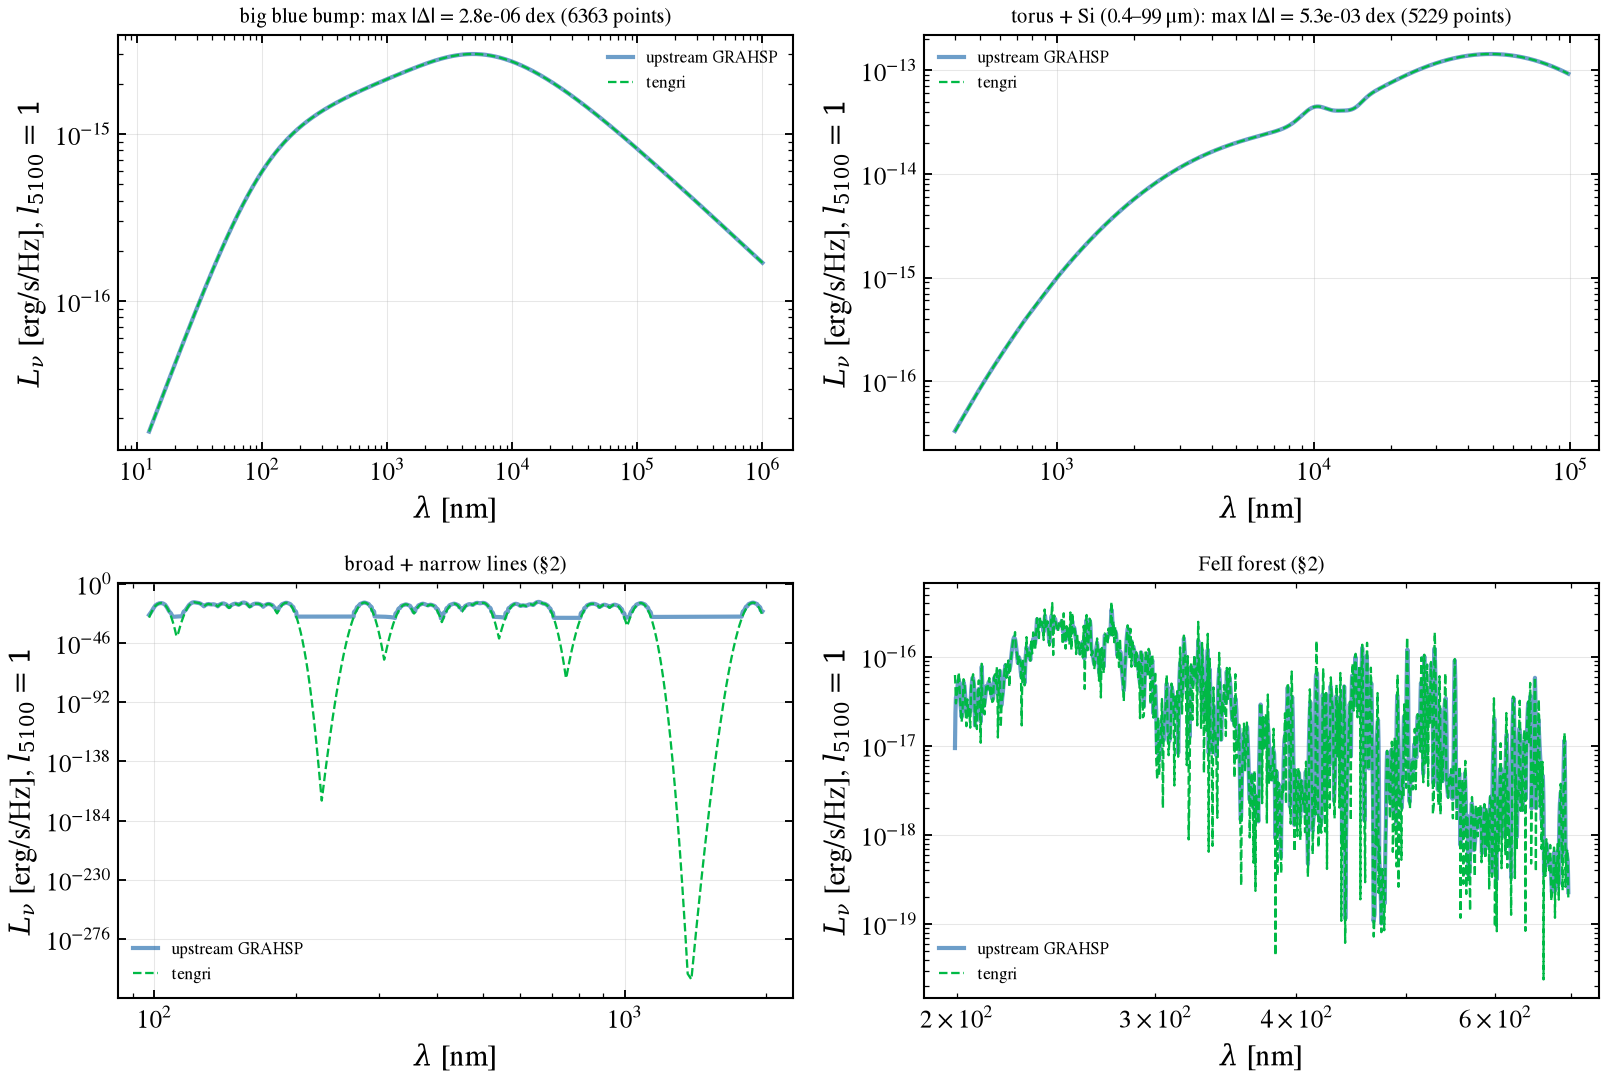

In [2]:
_pred = G.agn_predict(ssp, _up, a_feii=_up["afeii"])
_wm = np.asarray(_pred.wave_rest) * 0.1  # tengri model grid [nm]
_disc_t = G.lambda_l_lambda_per_nm(_pred, "sed_agn_disc")
_torus_t = G.lambda_l_lambda_per_nm(_pred, "sed_agn_torus")  # includes the Si feature
_lines_full_t = G.lambda_l_lambda_per_nm(_pred, "sed_agn_lines")  # broad + narrow + FeII
_pred_nofe = G.agn_predict(ssp, _up, a_feii=0.0)
_lines_t = G.lambda_l_lambda_per_nm(_pred_nofe, "sed_agn_lines")  # broad + narrow only
_feii_t = _lines_full_t - _lines_t

_disc_u = G.upstream_on(_wm, _fid.wave_nm, _fid.spectra["disc"])
_torus_u = G.upstream_on(_wm, _fid.wave_nm, _fid.spectra["torus"] + _fid.spectra["si"])
_lines_u = G.upstream_on(_wm, _fid.wave_nm, (_fid.spectra["bl"] + _fid.spectra["nl"]) / G.LINE_FLUX_SCALE)
_feii_u = G.upstream_on(_wm, _fid.wave_nm, _fid.spectra["feii"])
_all = np.ones_like(_wm, bool)

_panels = [
    ("big blue bump", _disc_t, _disc_u, _wm >= 12.4, True),
    ("torus + Si (0.4–99 μm)", _torus_t, _torus_u, (_wm >= 400.0) & (_wm <= 99000.0), True),
    ("broad + narrow lines (§2)", _lines_t, _lines_u, _all, False),
    ("FeII forest (§2)", _feii_t, _feii_u, _all, False),
]
_fig, _axes = plt.subplots(2, 2, figsize=(11, 7.5))
for _ax, (_title, _t, _u, _win, _pointwise) in zip(_axes.ravel(), _panels):
    _m = _win & (_u > 0) & (_t > 0)
    _ax.loglog(_wm[_m], to_lnu(_wm, _u)[_m], "C0-", lw=2.0, alpha=0.6, label="upstream GRAHSP")
    _ax.loglog(_wm[_m], to_lnu(_wm, _t)[_m], "C1--", lw=1.1, label="tengri")
    _ax.set_xlabel(r"$\lambda$ [nm]")
    _ax.set_ylabel(r"$L_\nu$ [erg/s/Hz], $l_{5100} = 1$")
    _ax.grid(True, alpha=0.3)
    _ax.legend(fontsize=8)
    if _pointwise:
        _n, _dex = G.dex_error(_t, _u, _win)
        _ax.set_title(f"{_title}: max |Δ| = {_dex:.1e} dex ({_n} points)", fontsize=10)
        print(f"§1 {_title:26s} max|Δ| = {_dex:.2e} dex over {_n} model-grid points")
    else:
        _ax.set_title(_title, fontsize=10)
_fig.tight_layout()
save_fig("grahsp_01_fiducial_components.png")

**Result.** The disc agrees to the printed level, and the torus agrees after the width correction
in section 4. The line and FeII panels are checked by integrals in section 2, because the model
grid does not resolve every line profile for a pointwise comparison.

## 2. Emission lines: flux, centroid and width

Sect. 2.1.2 sets each line's luminosity (2% of $L_\lambda(5100\,\text{Å})$ for broad H$\beta$, 0.2%
for narrow). Upstream integrates each line to $\sqrt{2}$ times that luminosity; the factor is
divided out here. The comparison is per line, over ±6σ windows
merged where lines overlap. Each window's integrated flux and flux-weighted centroid are compared.
Widths are compared for every window that holds a single line. Upstream's rendering of each line
is also measured on its own grid, to show where the width difference comes from.

§2 line windows: 10; single-line windows: 4; compared: 10 with flux above 1e-3 of the peak
 centre [nm] lines  flux ratio  centroid Δ [nm]  rms/σ tengri  rms/σ upstream
      103.07     2      0.9721          -0.0046           nan             nan
      149.39    10      0.9916           0.0599           nan             nan
      190.90     1      1.0066          -0.0034        1.0003          1.2156
      279.80     1      0.9985           0.0022        0.9997          1.2156
      365.69     3      0.9953          -0.0813           nan             nan
      468.77     5      0.9997           0.0203           nan             nan
      632.17     8      0.9985          -0.0333           nan             nan
      903.70     4      0.9958          -0.0491           nan             nan
     1083.00     1      0.9892          -0.0123        1.0092          1.2135
     1875.00     1      0.9958          -0.0437        0.9895          1.2156
§2 max |flux ratio − 1| = 2.79e-02 per window; tota

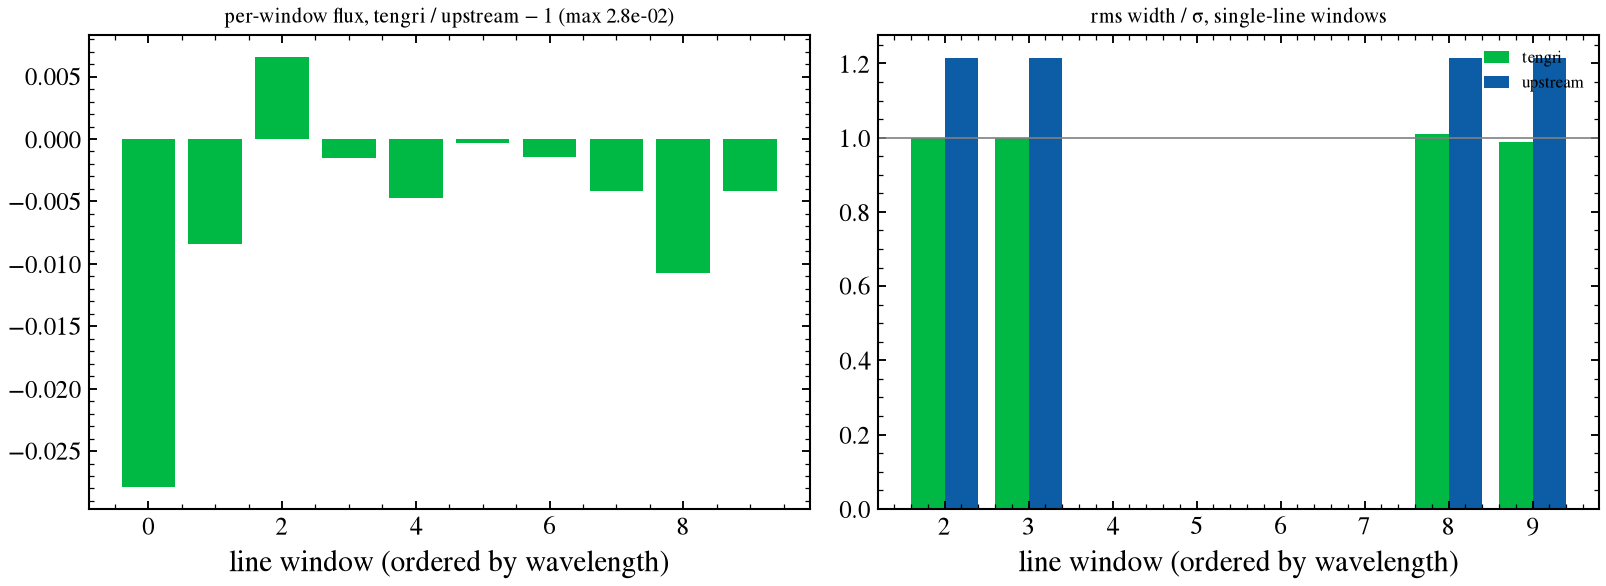

In [3]:
_lw = G.line_windows(G.line_centres_nm(), _up["linewidth"])
_centres = G.line_centres_nm()
_lines_u = G.upstream_on(_wm, _fid.wave_nm, (_fid.spectra["bl"] + _fid.spectra["nl"]) / G.LINE_FLUX_SCALE)
_tf, _tc, _tw = G.line_flux_centroid_width(_wm, _lines_t, _lw)
_uf, _uc, _uw = G.line_flux_centroid_width(_wm, _lines_u, _lw)
# Upstream's own profile on its own grid, unit-area-corrected, for the width of the same windows.
_native = (_fid.spectra["bl"] + _fid.spectra["nl"]) / G.LINE_FLUX_SCALE
_nf, _nc, _nw = G.line_flux_centroid_width(_fid.wave_nm, _native, _lw)

_sig_frac = _up["linewidth"] / G.C_KMS * G.FWHM_TO_SIGMA  # sigma / centre
_keep = _uf > 1e-3 * _uf.max()
print(f"§2 line windows: {len(_lw)}; single-line windows: "
      f"{sum(1 for lo, hi in _lw if np.sum((_centres >= lo) & (_centres <= hi)) == 1)}; "
      f"compared: {int(_keep.sum())} with flux above 1e-3 of the peak")
print(f"{'centre [nm]':>12s} {'lines':>5s} {'flux ratio':>11s} {'centroid Δ [nm]':>16s}"
      f" {'rms/σ tengri':>13s} {'rms/σ upstream':>15s}")
_rows = []
for k, (lo, hi) in enumerate(_lw):
    n_in = int(np.sum((_centres >= lo) & (_centres <= hi)))
    if not _keep[k]:
        continue
    centre = 0.5 * (lo + hi)
    sig = centre * _sig_frac
    rms_t = _tw[k] * _tc[k] / sig if n_in == 1 else np.nan
    rms_u = _nw[k] * _nc[k] / sig if n_in == 1 else np.nan
    _rows.append((centre, n_in, _tf[k] / _uf[k] - 1.0, _tc[k] - _uc[k], rms_t, rms_u))
    print(f"{centre:12.2f} {n_in:5d} {_tf[k] / _uf[k]:11.4f} {_tc[k] - _uc[k]:16.4f}"
          f" {rms_t:13.4f} {rms_u:15.4f}")
_iso = np.array([(r[4], r[5]) for r in _rows if r[1] == 1])
_flux_err = float(np.max(np.abs([r[2] for r in _rows])))
_tot_err = float(_tf.sum() / _uf.sum() - 1.0)
_cen_err = float(np.max(np.abs([r[3] for r in _rows])))
print(f"§2 max |flux ratio − 1| = {_flux_err:.2e} per window; total flux ratio − 1 = {_tot_err:+.2e}")
print(f"§2 max |centroid Δ| = {_cen_err:.2e} nm")
print(f"§2 single-line windows: tengri rms/σ in [{np.nanmin(_iso[:, 0]):.4f}, {np.nanmax(_iso[:, 0]):.4f}];"
      f" upstream rms/σ in [{np.nanmin(_iso[:, 1]):.4f}, {np.nanmax(_iso[:, 1]):.4f}]")

_fig, (_a0, _a1) = plt.subplots(1, 2, figsize=(11, 4.2))
_idx = np.arange(len(_rows))
_a0.bar(_idx, [r[2] for r in _rows], color="C1")
_a0.set_title(f"per-window flux, tengri / upstream − 1 (max {_flux_err:.1e})", fontsize=10)
_a0.set_xlabel("line window (ordered by wavelength)")
_a1.bar(_idx - 0.2, [r[4] for r in _rows], width=0.4, color="C1", label="tengri")
_a1.bar(_idx + 0.2, [r[5] for r in _rows], width=0.4, color="C0", label="upstream")
_a1.axhline(1.0, color="0.5", lw=0.8)
_a1.set_title("rms width / σ, single-line windows", fontsize=10)
_a1.set_xlabel("line window (ordered by wavelength)")
_a1.legend(fontsize=8)
_fig.tight_layout()
save_fig("grahsp_02_lines_integrals.png")

**Result.** Per-window fluxes agree to 2.8% (total −0.7%), and centroids
to 0.08 nm. tengri's lines have the Gaussian width: rms/σ lies between 0.990 and 1.009 for
every single-line window. Upstream's lines are about 22% wider. Its code evaluates each line at
nine points across ±3 FWHM and interpolates linearly between them, in `activatelines.py`. That
rendering broadens the profile; the 22% width difference is its cause, not a difference in
tengri's line strengths.

## 3. Balmer continuum

The Balmer continuum is switched on with `a_bc` for the two `abc` sets. Upstream follows Grandi
(1982) and smooths the continuum with a Gaussian of $\sigma$ equal to the FWHM; tengri uses
$\sigma = \mathrm{FWHM}/2.355$. The shapes therefore differ pointwise, and the comparison uses the
integral over 210–355 nm, which the continuum occupies, and over 210–250 nm, where neither code
smooths. The tengri continuum is the difference between the model with `a_bc` and the model
without it.

In [4]:
for _name in [n for n in SETS if G.load_set(n).params.get("abc", 0) != 0]:
    _s = G.load_set(_name)
    _u = _s.params
    _p_bc = G.agn_predict(ssp, _u, a_feii=0.0, a_bc=_u["abc"])
    _p_0 = G.agn_predict(ssp, _u, a_feii=0.0, a_bc=0.0)
    _bc_t = G.lambda_l_lambda_per_nm(_p_bc, "sed_agn_lines") - G.lambda_l_lambda_per_nm(_p_0, "sed_agn_lines")
    _wb = np.asarray(_p_bc.wave_rest) * 0.1
    _bc_u = G.upstream_on(_wb, _s.wave_nm, _s.spectra["balmer"])
    _win = (_wb >= 210.0) & (_wb <= 355.0)
    _blue = (_wb >= 210.0) & (_wb <= 250.0)
    _rel = np.trapezoid(_bc_t[_win], _wb[_win]) / np.trapezoid(_bc_u[_win], _wb[_win]) - 1.0
    _rel_b = np.trapezoid(_bc_t[_blue], _wb[_blue]) / np.trapezoid(_bc_u[_blue], _wb[_blue]) - 1.0
    print(f"§3 {_name}: 210–355 nm integral ratio − 1 = {_rel:+.2e}; 210–250 nm = {_rel_b:+.2e}")

§3 abc_0_p3: 210–355 nm integral ratio − 1 = +1.27e-03; 210–250 nm = +6.13e-06
§3 abc_1_p0: 210–355 nm integral ratio − 1 = +1.27e-03; 210–250 nm = +6.13e-06


**Result.** The integral over 210–355 nm agrees to +1.3×10⁻³, and the blue band 210–250 nm to +6×10⁻⁶. The residual in the full band is the smoothing difference: upstream smooths with σ equal to the FWHM, tengri with FWHM/2.355.

## 4. Torus width (the missing ½)

Upstream's cool and hot components use $\exp(-x^2/W^2)$. Eq. 2 of Buchner et al. (2024) is written
in wavelength, $\exp[-(\lambda-\lambda_\mathrm{COOL})^2/(2W^2)]$, with $W$ in dex. In logarithmic
form, the same component is $\exp[-(\log\lambda-\log\lambda_0)^2/(2W^2)]$, the log-quadratic
shape the paper describes. Upstream's $\exp(-x^2/W^2)$ therefore has $\sqrt{2}$ too large a
width, and tengri receives $W/\sqrt{2}$. The figure also shows the uncorrected value, for the two
cool-component widths in the sweep.

§4 coolwidth_0_p35: max |Δ| uncorrected = 7.994e-01 dex, corrected = 5.292e-03 dex
§4 coolwidth_0_p55: max |Δ| uncorrected = 3.087e-01 dex, corrected = 5.256e-03 dex


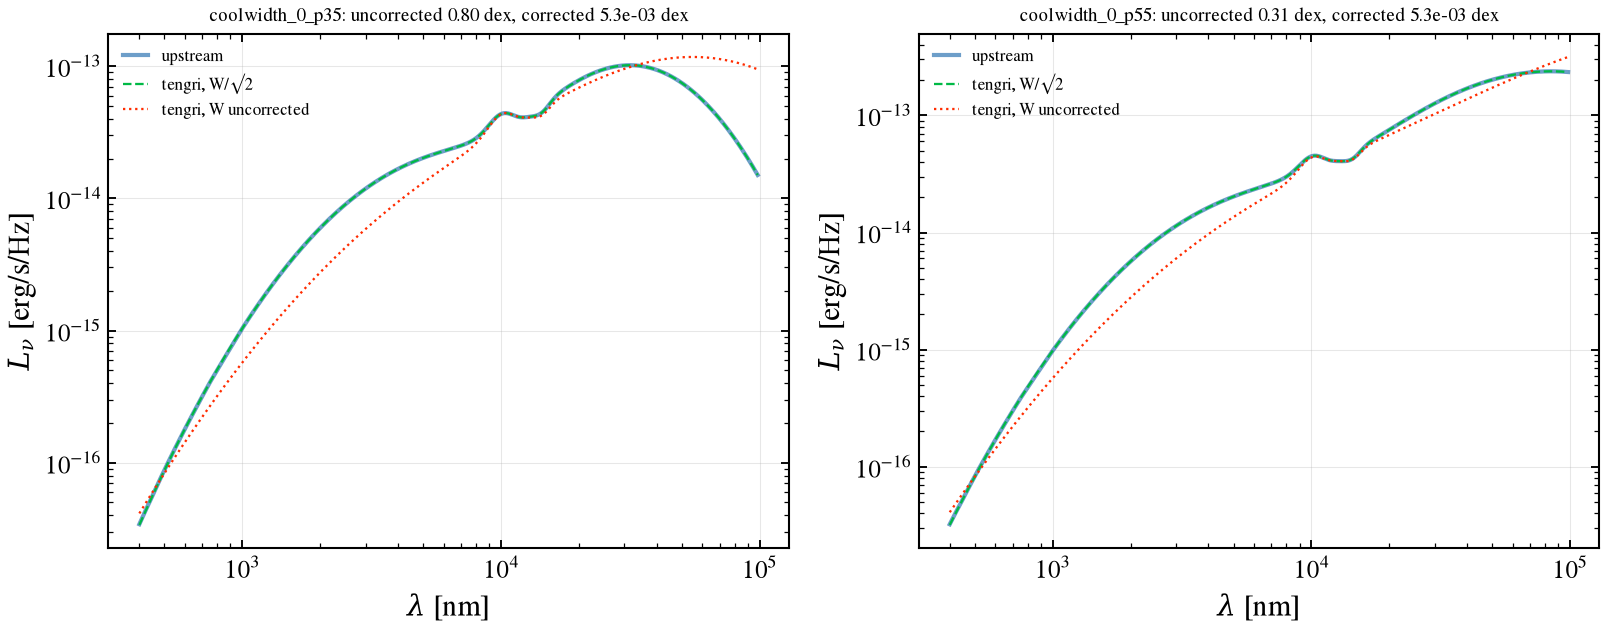

In [5]:
_fig, _axes = plt.subplots(1, 2, figsize=(11, 4.5))
for _ax, _name in zip(_axes, ("coolwidth_0_p35", "coolwidth_0_p55")):
    _s = G.load_set(_name)
    _u = _s.params
    _pc = G.agn_predict(ssp, _u, a_feii=_u["afeii"], width_correction=True)
    _pu = G.agn_predict(ssp, _u, a_feii=_u["afeii"], width_correction=False)
    _wt = np.asarray(_pc.wave_rest) * 0.1
    _tc = G.lambda_l_lambda_per_nm(_pc, "sed_agn_torus")
    _tu = G.lambda_l_lambda_per_nm(_pu, "sed_agn_torus")
    _ref = G.upstream_on(_wt, _s.wave_nm, _s.spectra["torus"] + _s.spectra["si"])
    _win = (_wt >= 400.0) & (_wt <= 99000.0)
    _, _dc = G.dex_error(_tc, _ref, _win)
    _, _du = G.dex_error(_tu, _ref, _win)
    _m = _win & (_ref > 0)
    _ax.loglog(_wt[_m], to_lnu(_wt, _ref)[_m], "C0-", lw=2.0, alpha=0.6, label="upstream")
    _ax.loglog(_wt[_m], to_lnu(_wt, _tc)[_m], "C1--", lw=1.1, label="tengri, W/√2")
    _ax.loglog(_wt[_m], to_lnu(_wt, _tu)[_m], "C3:", lw=1.1, label="tengri, W uncorrected")
    _ax.set_title(f"{_name}: uncorrected {_du:.2f} dex, corrected {_dc:.1e} dex", fontsize=9)
    _ax.set_xlabel(r"$\lambda$ [nm]")
    _ax.set_ylabel(r"$L_\nu$ [erg/s/Hz]")
    _ax.grid(True, alpha=0.3)
    _ax.legend(fontsize=8)
    print(f"§4 {_name}: max |Δ| uncorrected = {_du:.3e} dex, corrected = {_dc:.3e} dex")
_fig.tight_layout()
save_fig("grahsp_03_torus_width.png")

**Result.** Without the width correction the torus misses upstream by 0.80 dex at the 0.35 dex cool width, and by 0.31 dex at 0.55 dex. With W/√2 both agree to 5×10⁻³ dex. That residual is the interpolation of upstream's torus onto the model grid.

## 5. Netzer disc and MN12 torus: the 510 normalization

The paper's relation is $\lambda L_\lambda(5100\,\text{Å}) = l_5100$ (Eq. 1, Sect. 2.1.1 for the
disc; Eq. 4 for the torus at 12 μm). Upstream's `activatedisk` and `activatetorus` normalize each
template to $L_\lambda(510\,\mathrm{nm}) = 1$ per nm and multiply by $l_\mathrm{agn} = 1$. Their
$\lambda L_\lambda(510\,\mathrm{nm})$ is therefore 510. Both upstream spectra are divided by 510
before comparison, and the torus is compared in absolute units, so the factor is tested. The
tengri blocks are `grahsp_netzer` and `grahsp_mn12`, at the fiducial parameters.

§5 Netzer upstream vs its linear template (after /510): max|Δ| = 6.27e-03 dex
§5 Netzer tengri/upstream,     12.4–100      nm: median = +0.0005 dex, max|Δ| = 7.36e-04 dex over 993 points
§5 Netzer tengri/upstream,      100–1000     nm: median = +0.0001 dex, max|Δ| = 2.43e-03 dex over 5334 points
§5 Netzer tengri/upstream,     1000–10000    nm: median = -0.0234 dex, max|Δ| = 4.17e-01 dex over 667 points
§5 Netzer tengri/upstream,    10000–100000   nm: median = -1.6079 dex, max|Δ| = 3.57e+00 dex over 379 points
§5 Netzer tengri/upstream,   100000–1e+06    nm: median = -5.4716 dex, max|Δ| = 6.88e+00 dex over 378 points
§5 share of the Netzer disc's luminosity at 1000–10000 nm: 3.64e-02
§5 share of the Netzer disc's luminosity at 10000–100000 nm: 1.12e-04
§5 share of the Netzer disc's luminosity at 100000–1e+06 nm: 1.22e-07


§5 MN12 torus+Si, absolute, lambda L(12 μm): tengri 1.0338, upstream/510 1.0343
§5 MN12 torus+Si, 2–20 μm, absolute: max|Δ| = 3.30e-03 dex
§5 MN12 torus+Si, 20–99 μm, absolute: max|Δ| = 0.188 dex


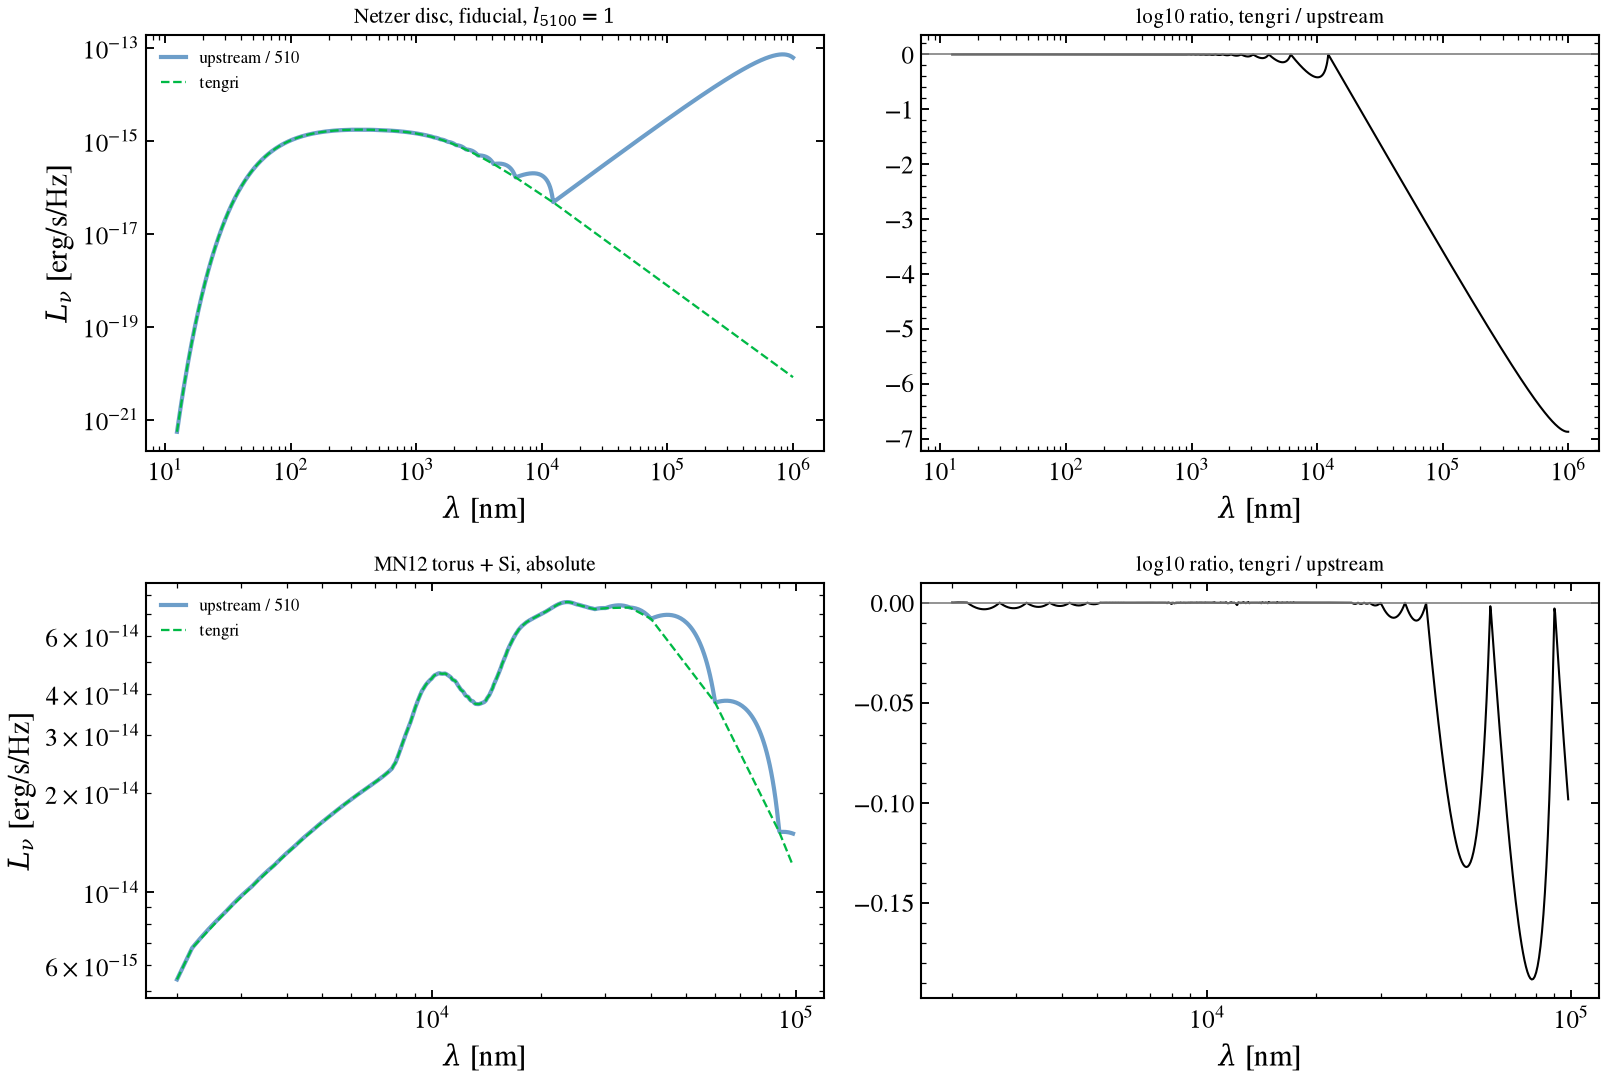

In [6]:
_nz_pred = G.agn_predict(ssp, _up, disc="grahsp_netzer", a_feii=_up["afeii"])
_wn = np.asarray(_nz_pred.wave_rest) * 0.1
_nz_t = G.lambda_l_lambda_per_nm(_nz_pred, "sed_agn_disc")
_nz_u = G.upstream_on(_wn, _fid.wave_nm, _fid.spectra["netzer"]) / G.UPSTREAM_510_FACTOR
_tw, _tl = G.netzer_template()
_lin_ref = np.interp(_wn, _tw, _tl) / G.UPSTREAM_510_FACTOR
print(f"§5 Netzer upstream vs its linear template (after /510): max|Δ| = "
      f"{G.dex_error(_nz_u, _lin_ref, np.ones_like(_wn, bool))[1]:.2e} dex")

_bands = ((12.4, 100.0), (100.0, 1000.0), (1000.0, 1e4), (1e4, 1e5), (1e5, 1e6))
for _lo, _hi in _bands:
    _m = (_wn >= _lo) & (_wn < _hi) & (_nz_t > 0) & (_nz_u > 0)
    _r = np.log10(_nz_t[_m] / _nz_u[_m])
    print(f"§5 Netzer tengri/upstream, {_lo:>8g}–{_hi:<8g} nm: median = {np.median(_r):+.4f} dex, "
          f"max|Δ| = {np.max(np.abs(_r)):.2e} dex over {_m.sum()} points")

# Share of the Netzer disc's luminosity (tengri, integrated over frequency) in each band.
_nu = _C_NM / _wn
_order = np.argsort(_nu)
_lnu_n = to_lnu(_wn, _nz_t)[_order]
_nu_s = _nu[_order]
_total = np.trapezoid(_lnu_n, _nu_s)
for _lo, _hi in ((1000.0, 1e4), (1e4, 1e5), (1e5, 1e6)):
    _sel = (_nu_s >= _C_NM / _hi) & (_nu_s <= _C_NM / _lo)
    _sub = np.trapezoid(_lnu_n[_sel], _nu_s[_sel])
    print(f"§5 share of the Netzer disc's luminosity at {_lo:g}–{_hi:g} nm: {_sub / _total:.2e}")

_mn_pred = G.agn_predict(ssp, _up, torus="grahsp_mn12", a_feii=_up["afeii"])
_wmn = np.asarray(_mn_pred.wave_rest) * 0.1
_mn_t = G.lambda_l_lambda_per_nm(_mn_pred, "sed_agn_torus")  # absolute, includes Si
_mn_u = G.upstream_on(_wmn, _fid.wave_nm, _fid.spectra["mn12_torus"] + _fid.spectra["mn12_si"]) / G.UPSTREAM_510_FACTOR
_w20 = (_wmn >= 2000.0) & (_wmn <= 20000.0)
_w_far = (_wmn >= 20000.0) & (_wmn <= 99000.0)
print(f"§5 MN12 torus+Si, absolute, lambda L(12 μm): tengri {12000.0 * np.interp(12000.0, _wmn, _mn_t):.4f},"
      f" upstream/510 {12000.0 * np.interp(12000.0, _wmn, _mn_u):.4f}")
print(f"§5 MN12 torus+Si, 2–20 μm, absolute: max|Δ| = {G.dex_error(_mn_t, _mn_u, _w20)[1]:.2e} dex")
print(f"§5 MN12 torus+Si, 20–99 μm, absolute: max|Δ| = {G.dex_error(_mn_t, _mn_u, _w_far)[1]:.3f} dex")

_fig, (_a0, _a1) = plt.subplots(2, 2, figsize=(11, 7.5))
_mk = (_nz_u > 0) & (_nz_t > 0)
_a0[0].loglog(_wn[_mk], to_lnu(_wn, _nz_u)[_mk], "C0-", lw=2.0, alpha=0.6, label="upstream / 510")
_a0[0].loglog(_wn[_mk], to_lnu(_wn, _nz_t)[_mk], "C1--", lw=1.1, label="tengri")
_a0[0].set_title("Netzer disc, fiducial, $l_{5100} = 1$", fontsize=10)
_a0[0].set_xlabel(r"$\lambda$ [nm]")
_a0[0].set_ylabel(r"$L_\nu$ [erg/s/Hz]")
_a0[0].legend(fontsize=8)
_a0[1].semilogx(_wn[_mk], np.log10(_nz_t[_mk] / _nz_u[_mk]), "k-", lw=1.0)
_a0[1].axhline(0, color="0.5", lw=0.8)
_a0[1].set_title("log10 ratio, tengri / upstream", fontsize=10)
_a0[1].set_xlabel(r"$\lambda$ [nm]")
_m12 = (_wmn >= 2000.0) & (_wmn <= 99000.0)
_a1[0].loglog(_wmn[_m12], to_lnu(_wmn, _mn_u)[_m12], "C0-", lw=2.0, alpha=0.6, label="upstream / 510")
_a1[0].loglog(_wmn[_m12], to_lnu(_wmn, _mn_t)[_m12], "C1--", lw=1.1, label="tengri")
_a1[0].set_title("MN12 torus + Si, absolute", fontsize=10)
_a1[0].set_xlabel(r"$\lambda$ [nm]")
_a1[0].set_ylabel(r"$L_\nu$ [erg/s/Hz]")
_a1[0].legend(fontsize=8)
_a1[1].semilogx(_wmn[_m12], np.log10(_mn_t[_m12] / _mn_u[_m12]), "k-", lw=1.0)
_a1[1].axhline(0, color="0.5", lw=0.8)
_a1[1].set_title("log10 ratio, tengri / upstream", fontsize=10)
_a1[1].set_xlabel(r"$\lambda$ [nm]")
_fig.tight_layout()
save_fig("grahsp_04_netzer_mn12.png")

**Result.** Over 12.4–1000 nm the Netzer disc agrees with upstream, after dividing by 510, to 2.4×10⁻³ dex. Beyond about 1 μm the two codes differ. Between 1 and 10 μm the residual reaches 0.42 dex (median −0.02 dex), and that range carries 3.6% of the disc's luminosity. Beyond 10 μm the median is −1.6 dex (10–100 μm, 1.1×10⁻⁴ of the luminosity) and −5.5 dex (100 μm–1 mm, 1.2×10⁻⁷). The MN12 torus, in absolute units, matches the 510 factor: λL_λ(12 μm) is 1.0338 for tengri and 1.0343 for upstream/510, and the 2–20 μm residual is 3.3×10⁻³ dex.

**Caveat.** The Netzer template has one 2-dex gap in its table, between 12.3 μm and 1.24 mm, where the next node is 2 dex away. Upstream interpolates linearly in wavelength across the gap, so its spectrum runs straight down to the 1.24 mm node. tengri interpolates log-log, which continues the Rayleigh–Jeans tail across the gap, $L_\nu \propto \nu^{2}$, and is well motivated for that tail, though not exact. The 1–10 μm residual is the same convention applied to nodes 0.3 dex apart. For the infrared shape beyond 12 μm, use the Netzer disc only as a Rayleigh–Jeans extrapolation; the luminosity beyond 12 μm is below 10⁻⁴ of the disc total.

## 6. Full composite, fiducial and type 2

The composite sums each code's components at matched parameters, on tengri's grid. Both are
normalized to the disc continuum at 510 nm, which carries $\lambda L_\lambda = 1$ by construction.
The disc is compared above 12.4 nm. The type-2 set has no broad-line block and no FeII forest on
either side, so its composite is the disc, the torus with Si, and the narrow lines.

§6 fiducial composite: max |Δ| (12.4 nm – 99 μm, normalized) = 7.95e-02 dex at 274.8 nm
§6 optical (400–700 nm) tengri/upstream median = 0.9995, 16–84%: 0.9917–1.0045
§6 at 274.8 nm: lines tengri 5.006e-04, upstream 1.490e-03 (ratio 0.336); FeII upstream 1.010e-03


§6 type-2 composite: max |Δ| (12.4 nm – 99 μm, normalized) = 2.32e-02 dex
§6 type-2 narrow lines: total flux ratio − 1 = -7.955e-03; per-window max |Δ| = 2.79e-02 over 10 windows


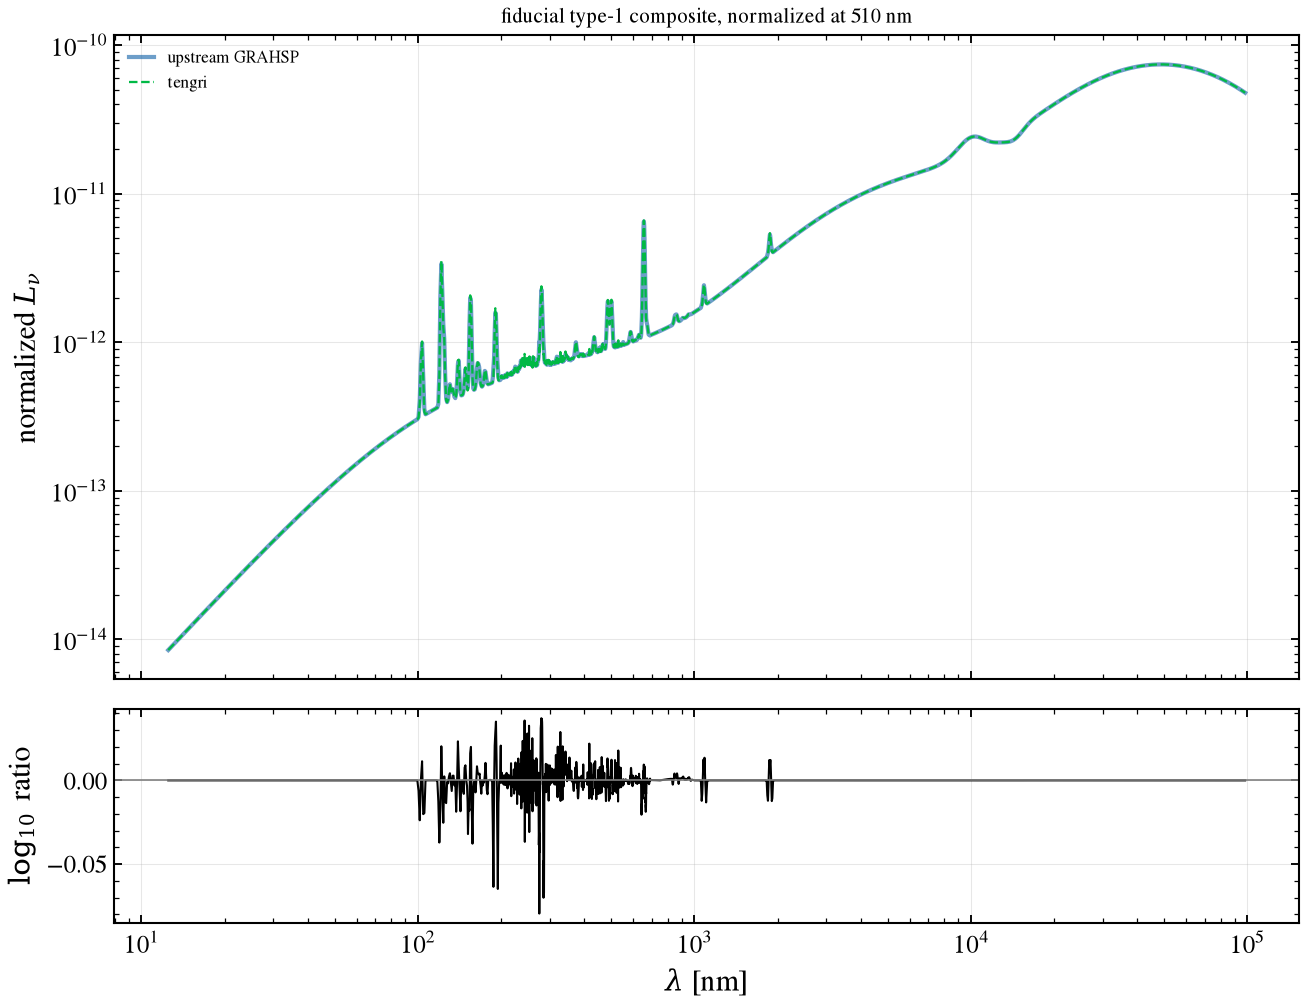

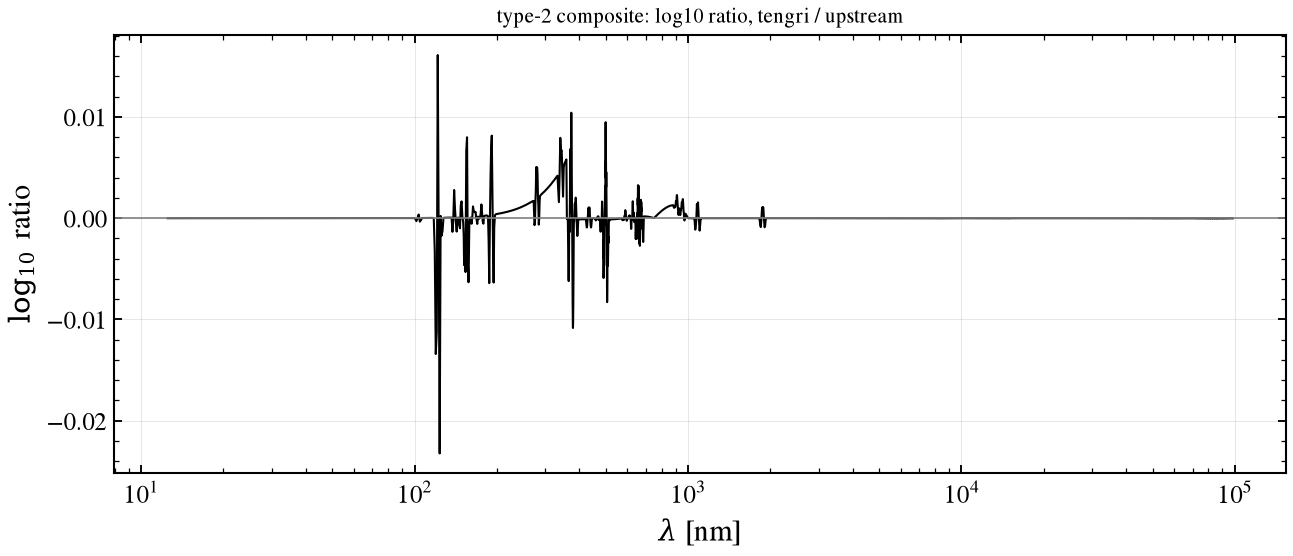

In [7]:
def _composite(pred_full, pred_nofe, s, *, narrow_only=False):
    """Matched-parameter composite on the model grid: tengri and upstream, both normalized."""
    wm = np.asarray(pred_full.wave_rest) * 0.1
    d_t = G.lambda_l_lambda_per_nm(pred_full, "sed_agn_disc")
    to_t = G.lambda_l_lambda_per_nm(pred_full, "sed_agn_torus")
    l_t = G.lambda_l_lambda_per_nm(pred_full, "sed_agn_lines")  # broad + narrow + FeII (if on)
    d_u = G.upstream_on(wm, s.wave_nm, s.spectra["disc"])
    to_u = G.upstream_on(wm, s.wave_nm, s.spectra["torus"] + s.spectra["si"])
    l_u = G.upstream_on(wm, s.wave_nm, (s.spectra["bl"] + s.spectra["nl"]) / G.LINE_FLUX_SCALE)
    f_u = G.upstream_on(wm, s.wave_nm, s.spectra["feii"])
    if narrow_only:
        f_u = 0.0 * f_u
    comp_t = d_t + to_t + l_t
    comp_u = d_u + to_u + l_u + f_u
    n_t = np.interp(510.0, wm, d_t)
    n_u = np.interp(510.0, wm, d_u)
    band = (wm >= 12.4) & (wm <= 99000.0) & (comp_u > 0) & (comp_t > 0)
    resid = np.log10((comp_t[band] / n_t) / (comp_u[band] / n_u))
    return wm, comp_t, comp_u, n_t, n_u, band, resid


_pf = G.agn_predict(ssp, _up, a_feii=_up["afeii"])
_pfn = G.agn_predict(ssp, _up, a_feii=0.0)
_wc, _ct, _cu, _nt, _nu_c, _bd, _res = _composite(_pf, _pfn, _fid)
_imax = int(np.argmax(np.abs(_res)))
_w_at = _wc[_bd][_imax]
_opt = (_wc >= 400.0) & (_wc <= 700.0)
_ratio = (_ct[_opt] / _nt) / (_cu[_opt] / _nu_c)
_lo, _med, _hi = np.percentile(_ratio, [16, 50, 84])
print(f"§6 fiducial composite: max |Δ| (12.4 nm – 99 μm, normalized) = {np.max(np.abs(_res)):.2e} dex at {_w_at:.1f} nm")
print(f"§6 optical (400–700 nm) tengri/upstream median = {_med:.4f}, 16–84%: {_lo:.4f}–{_hi:.4f}")

# The largest residual: the line profile upstream renders at that wavelength (see §2).
_ld = np.argmin(np.abs(_wc - _w_at))
_lt = G.lambda_l_lambda_per_nm(_pfn, "sed_agn_lines")[_ld]
_lu = np.interp(_w_at, _fid.wave_nm, (_fid.spectra["bl"] + _fid.spectra["nl"]) / G.LINE_FLUX_SCALE)
_fu = np.interp(_w_at, _fid.wave_nm, _fid.spectra["feii"])
print(f"§6 at {_w_at:.1f} nm: lines tengri {_lt:.3e}, upstream {_lu:.3e} (ratio {_lt / _lu:.3f});"
      f" FeII upstream {_fu:.3e}")

_fig, (_c0, _c1) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
_c0.loglog(_wc[_bd], to_lnu(_wc, _cu / _nu_c)[_bd], "C0-", lw=2.0, alpha=0.6, label="upstream GRAHSP")
_c0.loglog(_wc[_bd], to_lnu(_wc, _ct / _nt)[_bd], "C1--", lw=1.1, label="tengri")
_c0.set_ylabel(r"normalized $L_\nu$")
_c0.set_title("fiducial type-1 composite, normalized at 510 nm", fontsize=10)
_c0.legend(fontsize=8)
_c0.grid(True, alpha=0.3)
_c1.semilogx(_wc[_bd], _res, "k-", lw=1.0)
_c1.axhline(0, color="0.5", lw=0.8)
_c1.set_xlabel(r"$\lambda$ [nm]")
_c1.set_ylabel(r"$\log_{10}$ ratio")
_c1.grid(True, alpha=0.3)
_fig.tight_layout()
save_fig("grahsp_05_fullsed_fiducial.png")

_t2 = G.load_set("type_2")
_up2 = _t2.params
_pt2 = G.agn_predict(ssp, _up2, narrow_only=True, a_feii=None)
_pt2n = _pt2
_wt2, _ct2, _cu2, _nt2, _nu2, _bd2, _res2 = _composite(_pt2, _pt2n, _t2, narrow_only=True)
_nl_t = G.lambda_l_lambda_per_nm(_pt2n, "sed_agn_lines")
_nl_u = G.upstream_on(_wt2, _t2.wave_nm, _t2.spectra["nl"] / G.LINE_FLUX_SCALE)
_nlf = G.line_windows(G.line_centres_nm(), _up2["linewidth"])
_ntf, _, _ = G.line_flux_centroid_width(_wt2, _nl_t, _nlf)
_nuf, _, _ = G.line_flux_centroid_width(_wt2, _nl_u, _nlf)
_nk = _nuf > 1e-3 * _nuf.max()
print(f"§6 type-2 composite: max |Δ| (12.4 nm – 99 μm, normalized) = {np.max(np.abs(_res2)):.2e} dex")
print(f"§6 type-2 narrow lines: total flux ratio − 1 = {_ntf.sum() / _nuf.sum() - 1.0:+.3e};"
      f" per-window max |Δ| = {np.max(np.abs(_ntf[_nk] / _nuf[_nk] - 1.0)):.2e} over {int(_nk.sum())} windows")
_fig, _ax = plt.subplots(figsize=(9, 4))
_ax.semilogx(_wt2[_bd2], _res2, "k-", lw=1.0)
_ax.axhline(0, color="0.5", lw=0.8)
_ax.set_title("type-2 composite: log10 ratio, tengri / upstream", fontsize=10)
_ax.set_xlabel(r"$\lambda$ [nm]")
_ax.set_ylabel(r"$\log_{10}$ ratio")
_ax.grid(True, alpha=0.3)
_fig.tight_layout()
save_fig("grahsp_06_fullsed_type2.png")

**Result.** Normalized on the disc continuum at 510 nm, the fiducial composite agrees with upstream to 0.080 dex at most, at 274.8 nm. That point lies in the Mg II wing of the 279.8 nm line: upstream's rendered line is 3.0 times tengri's there (the lines ratio is 0.34), while the FeII forest is upstream's own, so the residual is upstream's linear rendering, not tengri's line strength. Across the optical (400–700 nm) the median ratio is 0.9995, with 16–84% spread 0.992–1.005. The type-2 composite agrees to 0.023 dex; its narrow lines have a total flux ratio of −0.8%.

## 7. Accretion luminosity

The accretion side (disc, lines, FeII) above the 91.2 nm Lyman edge gives the bolometric check.
The bolometric luminosity is $\int L_\lambda\,d\lambda$, with $L_\lambda$ in erg/s/nm and the
wavelength in nm. Upstream's lines carry the unit-area factor, divided out as in section 2.

In [8]:
_m_bol = _wm >= 91.2
_tg_acc = (_disc_t + _lines_full_t)[_m_bol]
_up_acc = (_disc_u + _lines_u + _feii_u)[_m_bol]
_lb_t = float(np.trapezoid(_tg_acc, _wm[_m_bol]))
_lb_u = float(np.trapezoid(_up_acc, _wm[_m_bol]))
print(f"§7 accretion L_bol above 91.2 nm (fiducial, unit l5100): tengri/upstream = {_lb_t / _lb_u:.5f}")

§7 accretion L_bol above 91.2 nm (fiducial, unit l5100): tengri/upstream = 0.99869


## 8. Attenuation

The AGN side is attenuated by two screens: E(B-V) for the galaxy-wide screen and E(B-V)-AGN for
the AGN-only one, both following upstream's `biattenuation` module. The check is the attenuation
factor, the attenuated total divided by the intrinsic total, against upstream's
$(I + A)/I$ built from its intrinsic components $I$ and its signed attenuation differences $A$.
Two sets are shown: a galaxy screen with E(B-V) = 0.1, and an AGN screen with E(B-V)-AGN = 0.2.

In [9]:
_att_rows = []
for _name in ("ebv_0_p1", "ebv_agn_0_p2"):
    _s = G.load_set(_name)
    _u = _s.params
    _ebv = (float(_u["ebv"]), float(_u["ebv_agn"]))
    _p_att = G.agn_predict(ssp, _u, a_feii=_u["afeii"], ebv=_ebv)
    _p_int = G.agn_predict(ssp, _u, a_feii=_u["afeii"])
    _wa = np.asarray(_p_att.wave_rest) * 0.1
    _tot_att = np.asarray(_p_att.sed.components["sed_agn"])
    _tot_int = np.asarray(_p_int.sed.components["sed_agn"])
    _fac_t = _tot_att / np.where(_tot_int > 0, _tot_int, np.nan)
    _keys = ("disc", "bl", "nl", "feii", "balmer", "torus", "si")
    _I = sum(_s.spectra[k] for k in _keys)
    _A = sum(_s.attenuation[k] for k in _keys)
    _fac_u = np.where(_I > 0, (_I + _A) / np.where(_I > 0, _I, 1.0), np.nan)
    _fac_u = G.upstream_on(_wa, _s.wave_nm, np.nan_to_num(_fac_u, nan=1.0))
    _fac_pos = np.where(_fac_u > 0, _fac_u, 1.0)  # log10 only where the factor is positive
    _m = (_wa >= 12.4) & (_wa <= 99000.0) & (_fac_u > 0) & (np.abs(np.log10(_fac_pos)) > 1e-3) & np.isfinite(_fac_t)
    _resid_a = np.log10(_fac_t[_m] / _fac_u[_m])
    _dex = float(np.max(np.abs(_resid_a)))
    _wa_m = _wa[_m]
    _i = int(np.argmax(np.abs(_resid_a)))
    _att_rows.append((_name, _ebv, _dex, int(_m.sum()), float(np.min(_fac_u[_m]))))
    print(f"§8 {_name}: E(B-V) = {_ebv[0]}, E(B-V)-AGN = {_ebv[1]}; max |Δ| of the attenuation factor = "
          f"{_dex:.2e} dex over {int(_m.sum())} points; upstream factor down to {float(np.min(_fac_u[_m])):.3e}")
    print(f"§8 {_name}: largest residual at {_wa_m[_i]:.1f} nm, upstream factor {_fac_u[_m][_i]:.3e},"
          f" tengri factor {_fac_t[_m][_i]:.3e}; max |Δ| where upstream factor > 0.1:"
          f" {float(np.max(np.abs(_resid_a[_fac_u[_m] > 0.1]))) if np.any(_fac_u[_m] > 0.1) else float('nan'):.2e} dex")

§8 ebv_0_p1: E(B-V) = 0.1, E(B-V)-AGN = 0.0; max |Δ| of the attenuation factor = 1.87e-04 dex over 5741 points; upstream factor down to 4.547e-11
§8 ebv_0_p1: largest residual at 13.2 nm, upstream factor 2.053e-10, tengri factor 2.052e-10; max |Δ| where upstream factor > 0.1: 3.55e-07 dex
§8 ebv_agn_0_p2: E(B-V) = 0.0, E(B-V)-AGN = 0.2; max |Δ| of the attenuation factor = 2.13e-01 dex over 5795 points; upstream factor down to 6.431e-17
§8 ebv_agn_0_p2: largest residual at 15.5 nm, upstream factor 6.431e-17, tengri factor 1.050e-16; max |Δ| where upstream factor > 0.1: 6.10e-07 dex


**Result.** For the galaxy screen (E(B-V) = 0.1) the attenuation factor agrees to 1.9×10⁻⁴ dex over all points, and to 4×10⁻⁷ dex where upstream's factor exceeds 0.1. For the AGN screen (E(B-V)-AGN = 0.2) the residual is 0.21 dex, but only where upstream's factor falls below 10⁻¹⁰ (at 15.5 nm, the factor is 6×10⁻¹⁷); where it exceeds 0.1 the agreement is 6×10⁻⁷ dex. The deep-UV tail is at the precision of the comparison, not a physics difference.

## Summary

- **§1.** Disc agrees to 3×10⁻⁶ dex and the torus with Si to 5×10⁻³ dex on tengri's grid.
- **§2.** Per-window line flux within 2.8% (total −0.7%), centroid within 0.08 nm. Single-line widths: tengri 0.990–1.009 of σ; upstream 1.214–1.216 of σ, from its nine-node rendering in `activatelines.py`.
- **§3.** Balmer integral within 1.3×10⁻³ over 210–355 nm.
- **§4.** The factor of ½ in the paper's Eq. 2 is needed; with it, 5×10⁻³ dex.
- **§5.** Netzer agrees to 2.4×10⁻³ dex over 12.4 nm–1 μm. Beyond 1 μm the codes interpolate the same template differently; that carries 3.6% of the luminosity at 1–10 μm and under 10⁻⁴ beyond. The MN12 torus agrees to 3.3×10⁻³ dex over 2–20 μm in absolute units.
- **§6.** Fiducial composite agrees to 0.080 dex at most, at the upstream Mg II wing; optical median 0.9995. Type-2 composite agrees to 0.023 dex.
- **§7.** Accretion luminosity above 91.2 nm agrees to 0.13%.
- **§8.** Attenuation factor agrees to 6×10⁻⁷ dex where it exceeds 0.1.

## References

- Buchner, J., Starck, H., Salvato, M., et al. 2024, A&A 692, A161, "Genuine Retrieval of the
  AGN Host Stellar Population (GRAHSP)", arXiv:2405.19297.
- Grandi, S. A. 1982, the Balmer-continuum model that upstream GRAHSP cites.
- The FeII and MN12 torus templates are repackaged from upstream GRAHSP's data files, with
  attribution to the upstream authors.